<a href="https://colab.research.google.com/github/trinidadperea/clasificador-pasteleria/blob/main/VisionTransformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install timm -q

In [ ]:
!wget -q http://data.vision.ee.ethz.ch/cvl/food-101.tar.gz
!tar -xzf food-101.tar.gz

In [ ]:
import os, random, shutil
random.seed(42)

CLASES = ["chocolate_cake", "apple_pie", "cup_cakes", "macarons", "donuts"]
BASE = "food-101"

def leer(nombre):
    return [l.strip() for l in open(f"{BASE}/meta/{nombre}.txt")]

train_all, test_all = leer("train"), leer("test")

def copiar(rutas, split, clase):
    destino = f"dataset/{split}/{clase}"
    os.makedirs(destino, exist_ok=True)
    for r in rutas:
        shutil.copy(f"{BASE}/images/{r}.jpg", destino)

for clase in CLASES:
    del_train = [r for r in train_all if r.startswith(clase + "/")]
    random.shuffle(del_train)
    corte = int(len(del_train) * 0.85)
    copiar(del_train[:corte], "train", clase)
    copiar(del_train[corte:], "val", clase)
    copiar([r for r in test_all if r.startswith(clase + "/")], "test", clase)

In [ ]:
for split in ["train", "val", "test"]:
    for c in sorted(CLASES):
        print(split, c, len(os.listdir(f"dataset/{split}/{c}")))

train apple_pie 637
train chocolate_cake 637
train cup_cakes 637
train donuts 637
train macarons 637
val apple_pie 113
val chocolate_cake 113
val cup_cakes 113
val donuts 113
val macarons 113
test apple_pie 250
test chocolate_cake 250
test cup_cakes 250
test donuts 250
test macarons 250


In [ ]:
import os
print(os.path.exists("dataset/train"))

True


In [ ]:
import copy
import torch, timm
from torch import nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

# --- Paso 2: modelo y datos ---
model = timm.create_model("vit_base_patch16_224", pretrained=True, num_classes=5)
cfg = timm.data.resolve_data_config({}, model=model)
mean, std = cfg["mean"], cfg["std"]
print(cfg)

tf_train = transforms.Compose([
    transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(mean, std)])
tf_eval = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(), transforms.Normalize(mean, std)])

train_ds = datasets.ImageFolder("dataset/train", tf_train)
val_ds = datasets.ImageFolder("dataset/val", tf_eval)
test_ds = datasets.ImageFolder("dataset/test", tf_eval)
print(train_ds.classes)

train_dl = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=64, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=64, num_workers=2)

# --- Paso 3: congelar la base, entrenar solo la cabeza ---
for p in model.parameters():
    p.requires_grad = False
head = model.get_classifier()
for p in head.parameters():
    p.requires_grad = True
model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(head.parameters(), lr=1e-3)

# --- Paso 4: entrenar con parada temprana ---
def evaluar(loader):
    model.eval(); total = correct = loss_sum = 0; y_true, y_pred = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += criterion(out, y).item() * len(y)
            p = out.argmax(1)
            correct += (p == y).sum().item(); total += len(y)
            y_true += y.cpu().tolist(); y_pred += p.cpu().tolist()
    return loss_sum / total, correct / total, y_true, y_pred

historial = {"train_acc": [], "val_acc": [], "train_loss": [], "val_loss": []}
mejor_loss, mejor_pesos, paciencia, sin_mejora = 1e9, None, 4, 0

for epoca in range(1, 16):
    model.train(); tot = ok = ls = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward(); optimizer.step()
        ls += loss.item() * len(y); ok += (out.argmax(1) == y).sum().item(); tot += len(y)
    v_loss, v_acc, _, _ = evaluar(val_dl)
    historial["train_loss"].append(ls / tot); historial["train_acc"].append(ok / tot)
    historial["val_loss"].append(v_loss); historial["val_acc"].append(v_acc)
    print(f"Época {epoca}: train acc {ok/tot:.3f} | val acc {v_acc:.3f} | val loss {v_loss:.3f}")
    if v_loss < mejor_loss:
        mejor_loss, sin_mejora = v_loss, 0
        mejor_pesos = copy.deepcopy(head.state_dict())
    else:
        sin_mejora += 1
        if sin_mejora >= paciencia:
            break

head.load_state_dict(mejor_pesos)

# --- Guardar en Drive apenas termina ---
from google.colab import drive
drive.mount("/content/drive")
torch.save(head.state_dict(), "/content/drive/MyDrive/vit_head.pt")
print("Guardado en Drive")

Dispositivo: cuda


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

{'input_size': (3, 224, 224), 'interpolation': 'bicubic', 'mean': (0.5, 0.5, 0.5), 'std': (0.5, 0.5, 0.5), 'crop_pct': 0.9, 'crop_mode': 'center'}
['apple_pie', 'chocolate_cake', 'cup_cakes', 'donuts', 'macarons']
Época 1: train acc 0.868 | val acc 0.920 | val loss 0.243
Época 2: train acc 0.943 | val acc 0.935 | val loss 0.210
Época 3: train acc 0.959 | val acc 0.940 | val loss 0.194
Época 4: train acc 0.970 | val acc 0.943 | val loss 0.194
Época 5: train acc 0.977 | val acc 0.947 | val loss 0.188
Época 6: train acc 0.981 | val acc 0.950 | val loss 0.197
Época 7: train acc 0.986 | val acc 0.949 | val loss 0.194
Época 8: train acc 0.987 | val acc 0.947 | val loss 0.198
Época 9: train acc 0.989 | val acc 0.952 | val loss 0.202
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Guardado en Drive


In [ ]:
from sklearn.metrics import classification_report

# Evaluación sobre el conjunto de test
test_loss, test_acc, y_true, y_pred = evaluar(test_dl)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

print("\nReporte de clasificación:\n")

print(classification_report(
    y_true,
    y_pred,
    target_names=test_ds.classes,
    digits=4
))

Test Loss: 0.1078
Test Accuracy: 96.72%

Reporte de clasificación:

                precision    recall  f1-score   support

     apple_pie     0.9917    0.9520    0.9714       250
chocolate_cake     0.9605    0.9720    0.9662       250
     cup_cakes     0.9416    0.9680    0.9546       250
        donuts     0.9639    0.9600    0.9619       250
      macarons     0.9801    0.9840    0.9820       250

      accuracy                         0.9672      1250
     macro avg     0.9675    0.9672    0.9672      1250
  weighted avg     0.9675    0.9672    0.9672      1250



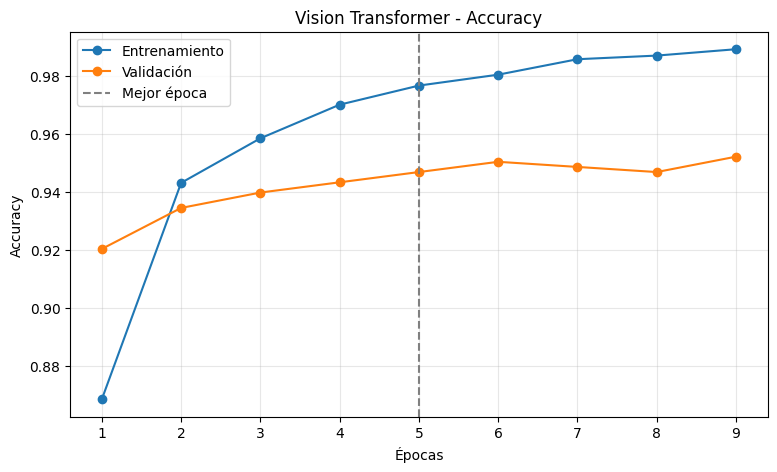

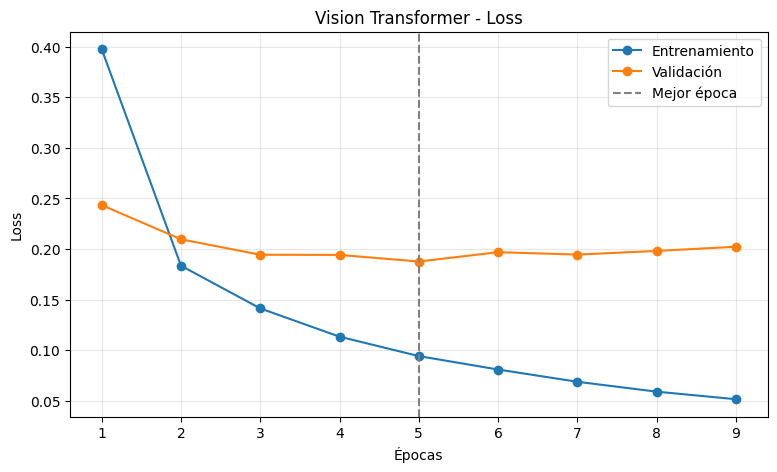

In [ ]:
import matplotlib.pyplot as plt

epocas = range(1, len(historial["train_acc"]) + 1)
mejor_epoca = historial["val_loss"].index(
    min(historial["val_loss"])
) + 1

# Gráfico de Accuracy
plt.figure(figsize=(9, 5))

plt.plot(epocas, historial["train_acc"],
         marker="o", label="Entrenamiento")

plt.plot(epocas, historial["val_acc"],
         marker="o", label="Validación")

plt.axvline(mejor_epoca, linestyle="--",
            color="gray", label="Mejor época")

plt.title("Vision Transformer - Accuracy")
plt.xlabel("Épocas")
plt.ylabel("Accuracy")
plt.xticks(list(epocas))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Gráfico de Loss
plt.figure(figsize=(9, 5))

plt.plot(epocas, historial["train_loss"],
         marker="o", label="Entrenamiento")

plt.plot(epocas, historial["val_loss"],
         marker="o", label="Validación")

plt.axvline(mejor_epoca, linestyle="--",
            color="gray", label="Mejor época")

plt.title("Vision Transformer - Loss")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.xticks(list(epocas))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

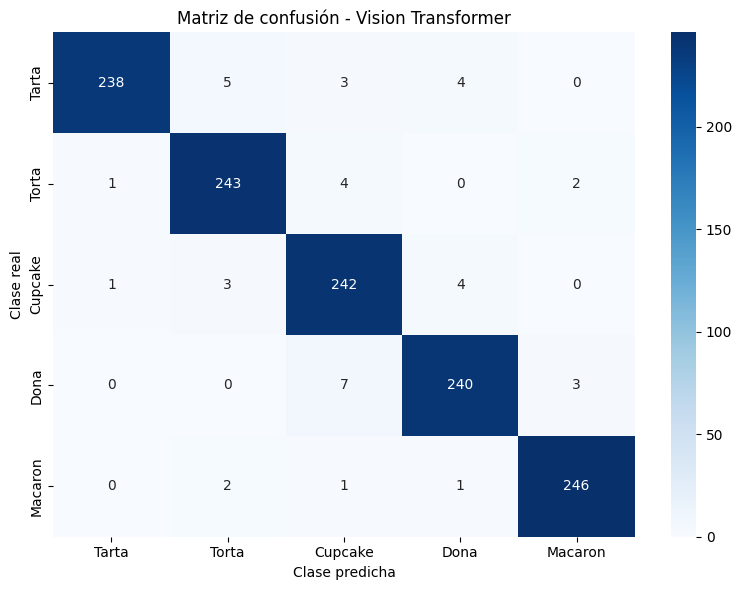

In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

nombres = ["Tarta", "Torta", "Cupcake", "Dona", "Macaron"]

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=nombres,
    yticklabels=nombres
)

plt.title("Matriz de confusión - Vision Transformer")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

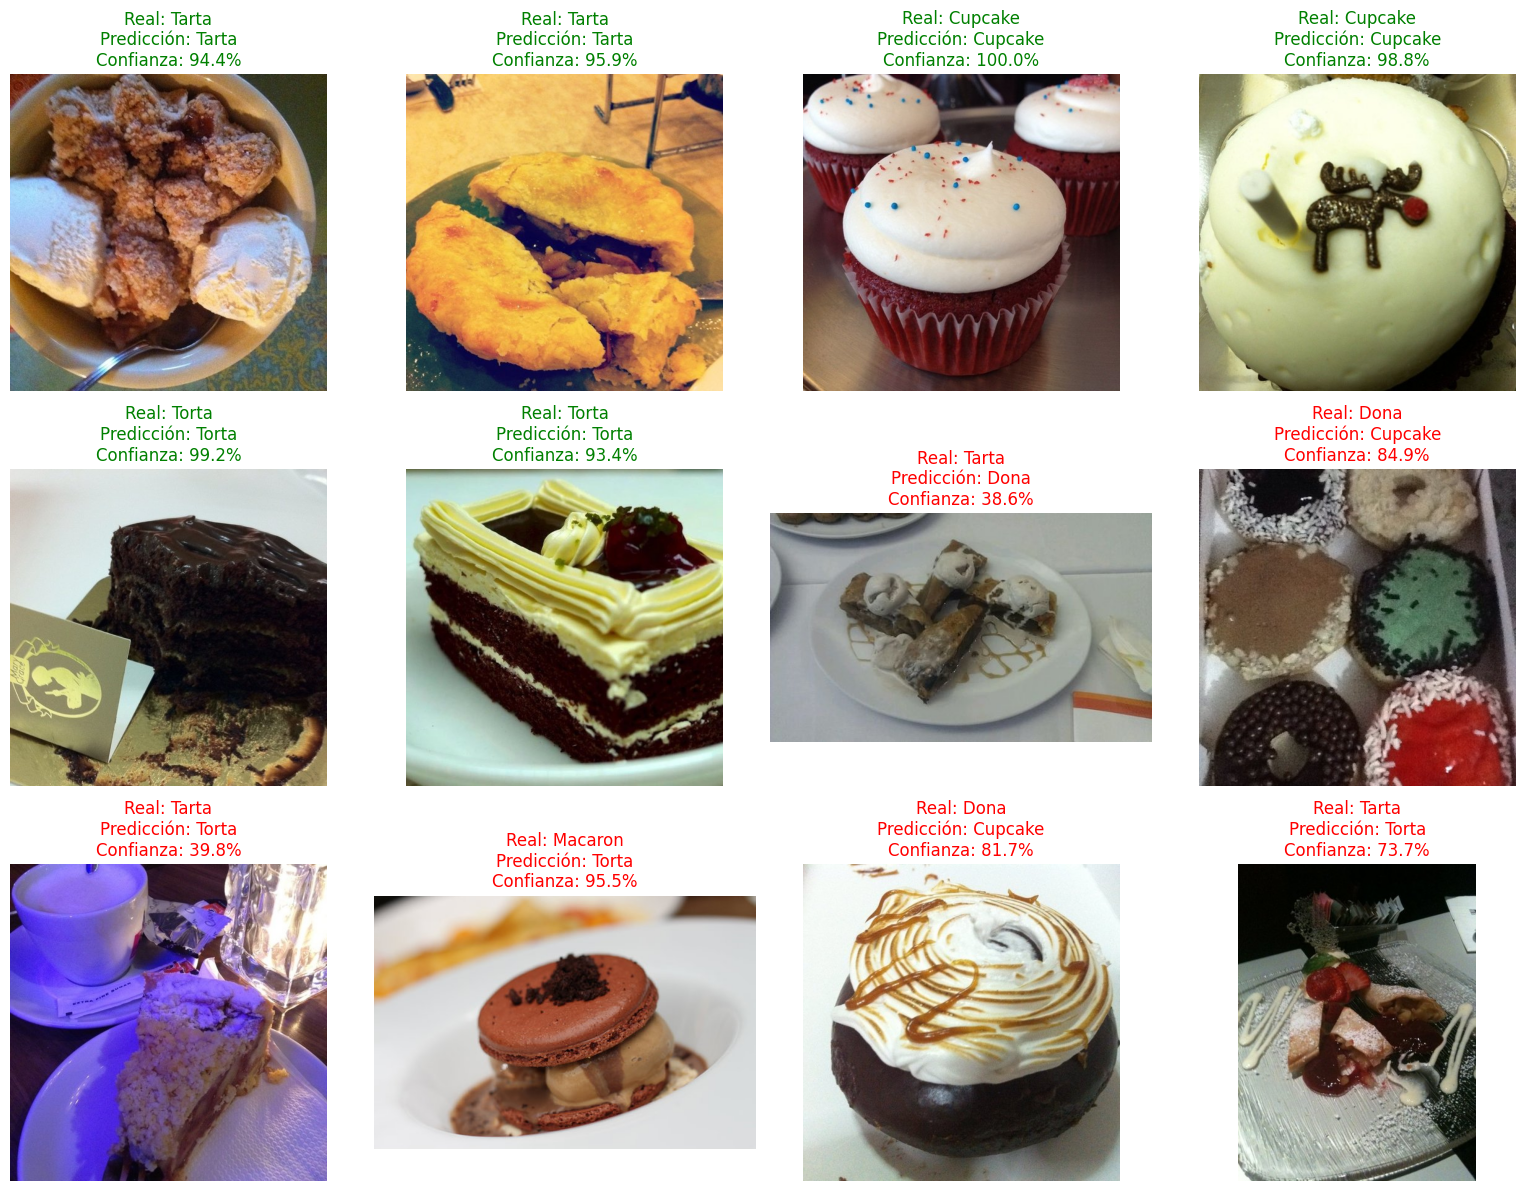

In [ ]:
import numpy as np
import random
import matplotlib.pyplot as plt
from PIL import Image

nombres = ["Tarta", "Torta", "Cupcake", "Dona", "Macaron"]

# Identificar predicciones correctas e incorrectas
correctas = [
    i for i in range(len(y_true))
    if y_true[i] == y_pred[i]
]

incorrectas = [
    i for i in range(len(y_true))
    if y_true[i] != y_pred[i]
]

# Seleccionar 6 aciertos y 6 errores
random.seed(42)

indices = (
    random.sample(correctas, 6) +
    random.sample(incorrectas, 6)
)

model.eval()

plt.figure(figsize=(16, 12))

for posicion, idx in enumerate(indices):

    ruta, etiqueta = test_ds.samples[idx]

    imagen = Image.open(ruta).convert("RGB")

    x = tf_eval(imagen).unsqueeze(0).to(device)

    with torch.no_grad():
        salida = model(x)
        probabilidades = torch.softmax(salida, dim=1)
        confianza, prediccion = probabilidades.max(dim=1)

    prediccion = prediccion.item()
    confianza = confianza.item() * 100

    color = "green" if prediccion == etiqueta else "red"

    plt.subplot(3, 4, posicion + 1)
    plt.imshow(imagen)

    plt.title(
        f"Real: {nombres[etiqueta]}\n"
        f"Predicción: {nombres[prediccion]}\n"
        f"Confianza: {confianza:.1f}%",
        color=color
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

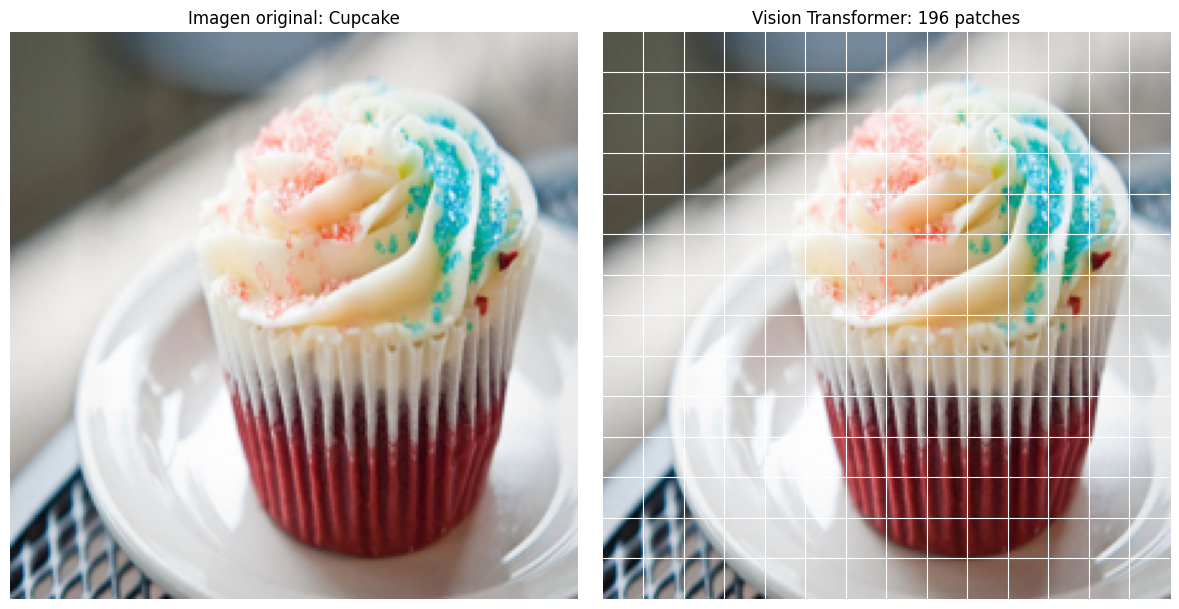

Tamaño de imagen: 224 x 224
Tamaño de patch: 16 x 16
Cantidad de patches: 196


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# Seleccionar una imagen correctamente clasificada
categoria = "cup_cakes"

candidatas = [
    i for i in correctas
    if test_ds.classes[y_true[i]] == categoria
]

idx = random.choice(candidatas)

ruta, etiqueta = test_ds.samples[idx]

imagen = Image.open(ruta).convert("RGB")
imagen = imagen.resize((224, 224))

imagen_np = np.array(imagen)

patch_size = 16
img_size = 224

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Imagen original redimensionada
axes[0].imshow(imagen_np)
axes[0].set_title(f"Imagen original: {nombres[etiqueta]}")
axes[0].axis("off")

# Imagen dividida en patches
axes[1].imshow(imagen_np)

for i in range(patch_size, img_size, patch_size):

    axes[1].axhline(
        i - 0.5,
        color="white",
        linewidth=0.8
    )

    axes[1].axvline(
        i - 0.5,
        color="white",
        linewidth=0.8
    )

axes[1].set_title("Vision Transformer: 196 patches")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Tamaño de imagen:", img_size, "x", img_size)
print("Tamaño de patch:", patch_size, "x", patch_size)
print("Cantidad de patches:", (img_size // patch_size)**2)

In [ ]:
print("Índice de la imagen:", idx)

Índice de la imagen: 507


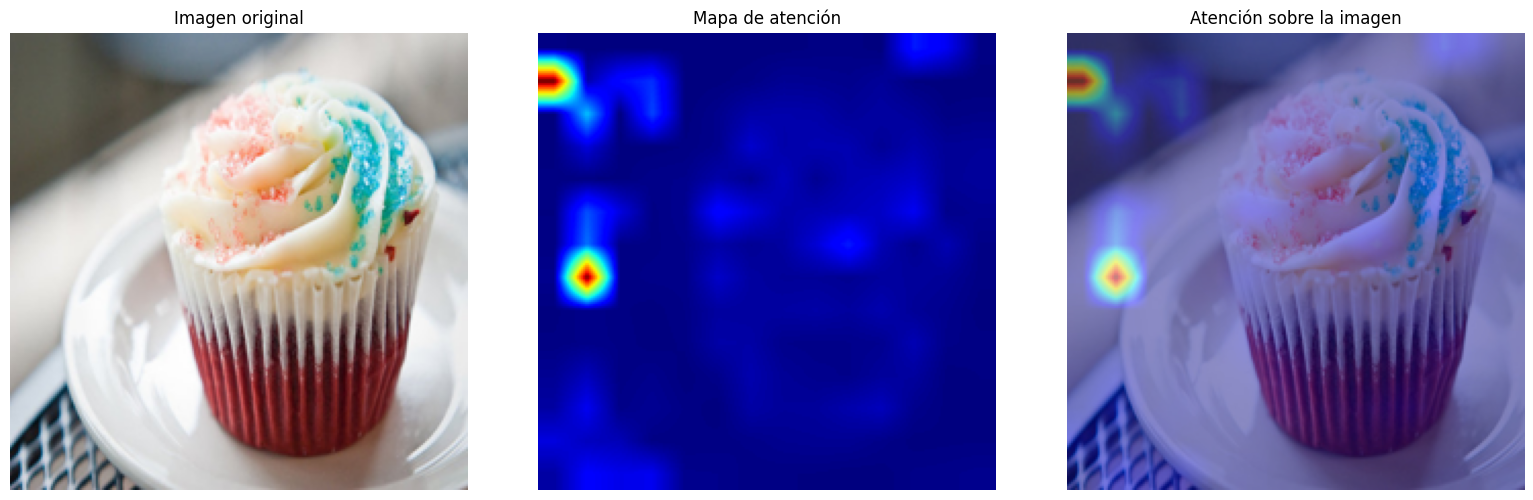

Clase real: Cupcake
Predicción: Cupcake
Confianza: 100.00%


In [ ]:
import torch.nn.functional as F

# Recuperar la misma imagen utilizada para los patches
ruta, etiqueta = test_ds.samples[idx]
imagen = Image.open(ruta).convert("RGB")

x = tf_eval(imagen).unsqueeze(0).to(device)

model.eval()

# Obtener el último bloque de atención
ultimo_bloque = model.blocks[-1].attn

# Almacenar los pesos de atención
attention_weights = []

def guardar_atencion(module, inputs, output):
    attention_weights.append(output.detach().cpu())

# Desactivar temporalmente la atención optimizada
estado_original = ultimo_bloque.fused_attn
ultimo_bloque.fused_attn = False

# Capturar los pesos reales de atención
hook = ultimo_bloque.attn_drop.register_forward_hook(
    guardar_atencion
)

try:
    with torch.no_grad():
        salida = model(x)
        probabilidades = torch.softmax(salida, dim=1)
        confianza, prediccion = probabilidades.max(dim=1)
finally:
    hook.remove()
    ultimo_bloque.fused_attn = estado_original

# Promediar las 12 cabezas de atención
attention = attention_weights[0][0].mean(dim=0)

# Atención del token CLS hacia los 196 patches
attention = attention[0, 1:]

# Reconstruir la cuadrícula de 14 x 14
attention = attention.reshape(14, 14)

# Redimensionar el mapa a 224 x 224
attention = F.interpolate(
    attention.unsqueeze(0).unsqueeze(0),
    size=(224, 224),
    mode="bilinear",
    align_corners=False
).squeeze().numpy()

# Normalizar los valores entre 0 y 1
attention = (
    (attention - attention.min()) /
    (attention.max() - attention.min() + 1e-8)
)

imagen_np = np.array(imagen.resize((224, 224)))

# Visualización
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(imagen_np)
axes[0].set_title("Imagen original")
axes[0].axis("off")

axes[1].imshow(attention, cmap="jet")
axes[1].set_title("Mapa de atención")
axes[1].axis("off")

axes[2].imshow(imagen_np)
axes[2].imshow(attention, cmap="jet", alpha=0.45)
axes[2].set_title("Atención sobre la imagen")
axes[2].axis("off")

plt.tight_layout()
plt.show()

print("Clase real:", nombres[etiqueta])
print("Predicción:", nombres[prediccion.item()])
print(f"Confianza: {confianza.item() * 100:.2f}%")

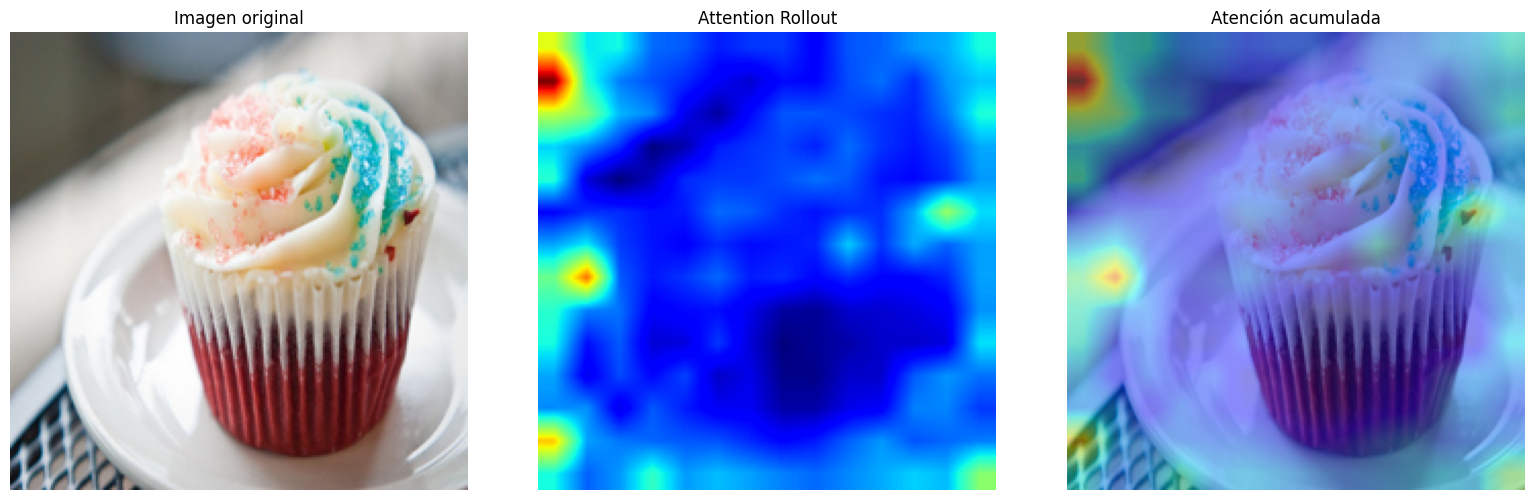

Bloques analizados: 12
Cantidad de tokens: 197


In [ ]:
import torch.nn.functional as F

model.eval()

# Utilizar la misma imagen del cupcake
ruta, etiqueta = test_ds.samples[idx]
imagen = Image.open(ruta).convert("RGB")
x = tf_eval(imagen).unsqueeze(0).to(device)

atenciones = []
hooks = []
estados_originales = []

def capturar_atencion(module, inputs, output):
    atenciones.append(output.detach().cpu())

# Capturar la atención de los 12 bloques
for bloque in model.blocks:

    estados_originales.append(bloque.attn.fused_attn)
    bloque.attn.fused_attn = False

    hook = bloque.attn.attn_drop.register_forward_hook(
        capturar_atencion
    )

    hooks.append(hook)

# Ejecutar el modelo
try:
    with torch.no_grad():
        salida = model(x)

finally:
    for hook in hooks:
        hook.remove()

    for bloque, estado in zip(
        model.blocks, estados_originales
    ):
        bloque.attn.fused_attn = estado

# Inicializar matriz de propagación
cantidad_tokens = atenciones[0].shape[-1]

identidad = torch.eye(cantidad_tokens)
rollout = identidad.clone()

# Combinar la atención de todos los bloques
for atencion in atenciones:

    # Promediar las cabezas de atención
    A = atencion[0].mean(dim=0).float()

    # Incorporar conexiones residuales
    A = A + identidad

    # Normalizar
    A = A / A.sum(dim=-1, keepdim=True)

    # Acumular la atención
    rollout = A @ rollout

# Atención acumulada del token CLS hacia los patches
mapa = rollout[0, 1:].reshape(14, 14)

# Redimensionar
mapa = F.interpolate(
    mapa.unsqueeze(0).unsqueeze(0),
    size=(224, 224),
    mode="bilinear",
    align_corners=False
).squeeze().numpy()

# Normalizar entre 0 y 1
mapa = (mapa - mapa.min()) / (
    mapa.max() - mapa.min() + 1e-8
)

imagen_np = np.array(imagen.resize((224, 224)))

# Visualización
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(imagen_np)
axes[0].set_title("Imagen original")
axes[0].axis("off")

axes[1].imshow(mapa, cmap="jet")
axes[1].set_title("Attention Rollout")
axes[1].axis("off")

axes[2].imshow(imagen_np)
axes[2].imshow(mapa, cmap="jet", alpha=0.45)
axes[2].set_title("Atención acumulada")
axes[2].axis("off")

plt.tight_layout()
plt.show()

print("Bloques analizados:", len(atenciones))
print("Cantidad de tokens:", cantidad_tokens)

In [ ]:
# Guardado definitivo del Vision Transformer

torch.save({
    "model_name": "vit_base_patch16_224",
    "model_state_dict": model.state_dict(),
    "classes": train_ds.classes,
    "num_classes": 5,
    "data_config": cfg,
    "historial": historial,
    "test_accuracy": test_acc,
    "test_loss": test_loss,
    "timm_version": timm.__version__,
    "torch_version": str(torch.__version__)
}, "/content/drive/MyDrive/modelo_vit_pasteleria.pt")

print("Modelo Vision Transformer guardado correctamente")

Modelo Vision Transformer guardado correctamente


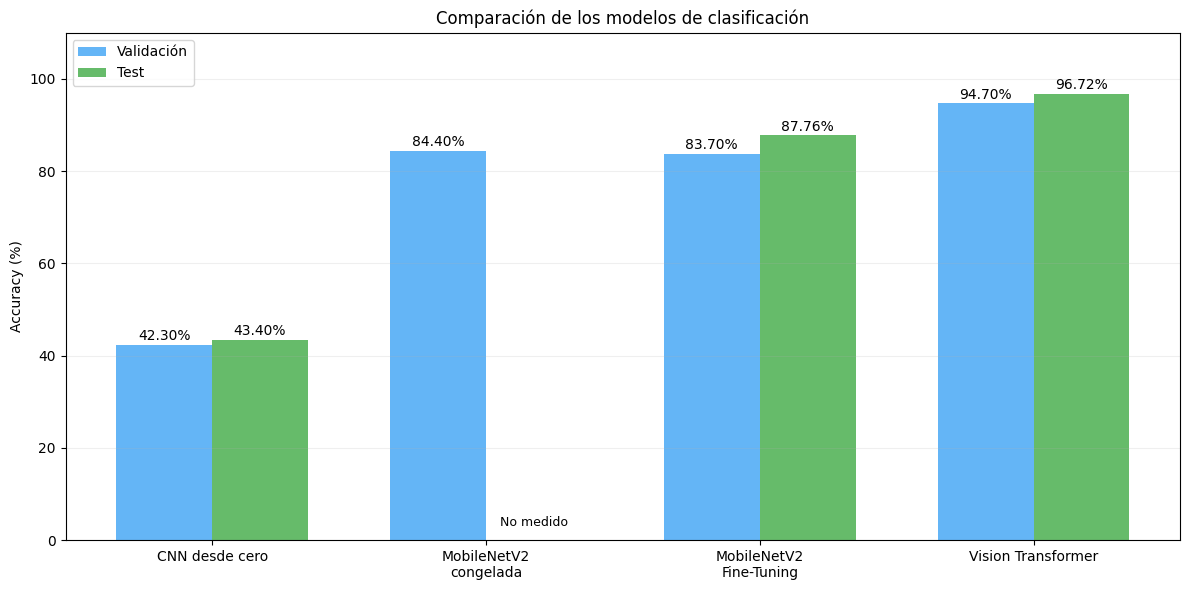

In [ ]:
# comparacion con los modelos originales
# comparacion acurracy
import matplotlib.pyplot as plt
import numpy as np

modelos = [
    "CNN desde cero",
    "MobileNetV2\ncongelada",
    "MobileNetV2\nFine-Tuning",
    "Vision Transformer"
]

validacion = [42.3, 84.4, 83.7, 94.7]
test = [43.4, np.nan, 87.76, 96.72]

x = np.arange(len(modelos))
ancho = 0.35

plt.figure(figsize=(12, 6))

b1 = plt.bar(
    x - ancho/2, validacion, ancho,
    label="Validación", color="#64B5F6"
)

b2 = plt.bar(
    x + ancho/2, test, ancho,
    label="Test", color="#66BB6A"
)

for barras in [b1, b2]:
    for barra in barras:
        altura = barra.get_height()

        if not np.isnan(altura):
            plt.text(
                barra.get_x() + barra.get_width()/2,
                altura + 1,
                f"{altura:.2f}%",
                ha="center",
                fontsize=10
            )

plt.text(
    x[1] + ancho/2, 3,
    "No medido",
    ha="center",
    fontsize=9
)

plt.xticks(x, modelos)
plt.ylabel("Accuracy (%)")
plt.title("Comparación de los modelos de clasificación")
plt.ylim(0, 110)
plt.legend()
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

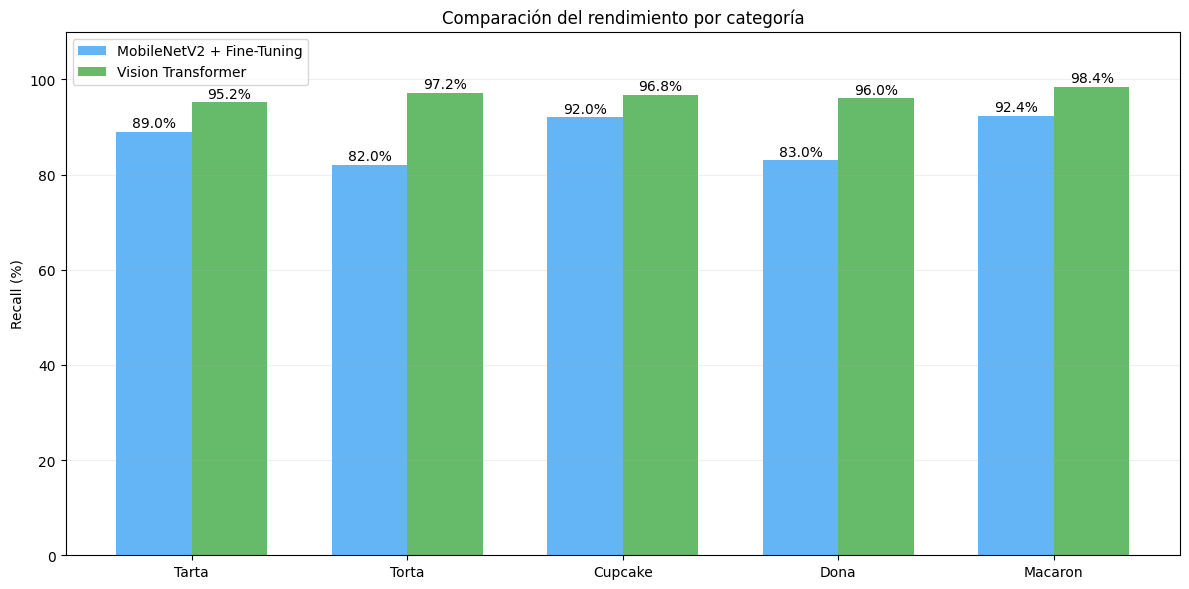

In [ ]:
categorias = [
    "Tarta", "Torta", "Cupcake", "Dona", "Macaron"
]

recall_mobilenet = [89, 82, 92, 83, 92.4]
recall_vit = [95.2, 97.2, 96.8, 96.0, 98.4]

x = np.arange(len(categorias))
ancho = 0.35

plt.figure(figsize=(12, 6))

b1 = plt.bar(
    x - ancho/2, recall_mobilenet, ancho,
    label="MobileNetV2 + Fine-Tuning",
    color="#64B5F6"
)

b2 = plt.bar(
    x + ancho/2, recall_vit, ancho,
    label="Vision Transformer",
    color="#66BB6A"
)

for barras in [b1, b2]:
    for barra in barras:
        altura = barra.get_height()

        plt.text(
            barra.get_x() + barra.get_width()/2,
            altura + 1,
            f"{altura:.1f}%",
            ha="center",
            fontsize=10
        )

plt.xticks(x, categorias)
plt.ylabel("Recall (%)")
plt.title("Comparación del rendimiento por categoría")
plt.ylim(0, 110)
plt.legend()
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
import random

base = Path("food-101")

clases_originales = [
    "chocolate_cake",
    "apple_pie",
    "cup_cakes",
    "macarons",
    "donuts"
]

rng = random.Random(42)

train_all = (base / "meta/train.txt").read_text().splitlines()
test_all = (base / "meta/test.txt").read_text().splitlines()

for clase in clases_originales:

    rutas = [
        r.strip() for r in train_all
        if r.startswith(clase + "/")
    ]

    rng.shuffle(rutas)
    corte = int(len(rutas) * 0.85)

    esperados = {
        "train": rutas[:corte],
        "val": rutas[corte:],
        "test": [
            r.strip() for r in test_all
            if r.startswith(clase + "/")
        ]
    }

    for split, archivos in esperados.items():

        original = {
            Path(r).name + ".jpg" for r in archivos
        }

        actual = {
            p.name for p in
            Path(f"dataset/{split}/{clase}").glob("*.jpg")
        }

        assert original == actual, f"Diferencia: {split}/{clase}"

print("Todas las particiones coinciden con el proyecto original")

Todas las particiones coinciden con el proyecto original
